In [22]:
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn import model_selection
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sb


In [23]:
# https://drive.google.com/file/d/1o1Ilpxk69avNJ0rP6DAooWObG6fE-EZ1/view?usp=sharing
file_id = '1o1Ilpxk69avNJ0rP6DAooWObG6fE-EZ1'
download_url = f'https://drive.google.com/uc?id={file_id}'
df = pd.read_csv(download_url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45.0,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2.0,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

# Asegurar que las tres variables sean numéricas
for columna in numericas:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

estadisticas = df[numericas].describe().T

estadisticas["Mediana"] = df[numericas].median()

estadisticas = estadisticas.rename(columns={
    "count": "Cantidad disponible",
    "mean": "Media",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "Primer cuartil",
    "50%": "Segundo cuartil",
    "75%": "Tercer cuartil",
    "max": "Máximo"
})

display(estadisticas.drop(columns="Segundo cuartil").round(2))

,Cantidad disponible,Media,Desviación estándar,Mínimo,Primer cuartil,Tercer cuartil,Máximo,Mediana
tenure,6824.0,32.27,24.57,0.0,9.0,55.00,72.00,29.00
MonthlyCharges,6824.0,64.61,30.14,18.4,35.2,89.85,118.75,70.30
TotalCharges,6815.0,2283.36,2264.18,18.8,400.7,3793.05,8684.80,1398.25


In [25]:
categoricas = [
    columna for columna in df.columns
    if columna not in numericas + ["customerID"]
]

for columna in categoricas:
    frecuencias = df[columna].value_counts(dropna=False)

    tabla = pd.DataFrame({
        "Frecuencia": frecuencias,
        "Porcentaje (%)": (frecuencias / len(df) * 100).round(2)
    })

    print(f"\nDistribución de {columna}:")
    display(tabla)


Distribución de gender:


,Frecuencia,Porcentaje (%)
gender,,
Male,3627,50.49
Female,3556,49.51



Distribución de SeniorCitizen:


,Frecuencia,Porcentaje (%)
SeniorCitizen,,
0,6016,83.75
1,1167,16.25



Distribución de Partner:


...

,Frecuencia,Porcentaje (%)
PaperlessBilling,,
Yes,4253,59.21
No,2930,40.79



Distribución de PaymentMethod:


,Frecuencia,Porcentaje (%)
PaymentMethod,,
Electronic check,2415,33.62
Mailed check,1642,22.86
Bank transfer (automatic),1573,21.90
Credit card (automatic),1553,21.62



Distribución de Churn:


,Frecuencia,Porcentaje (%)
Churn,,
No,5270,73.37
Yes,1913,26.63


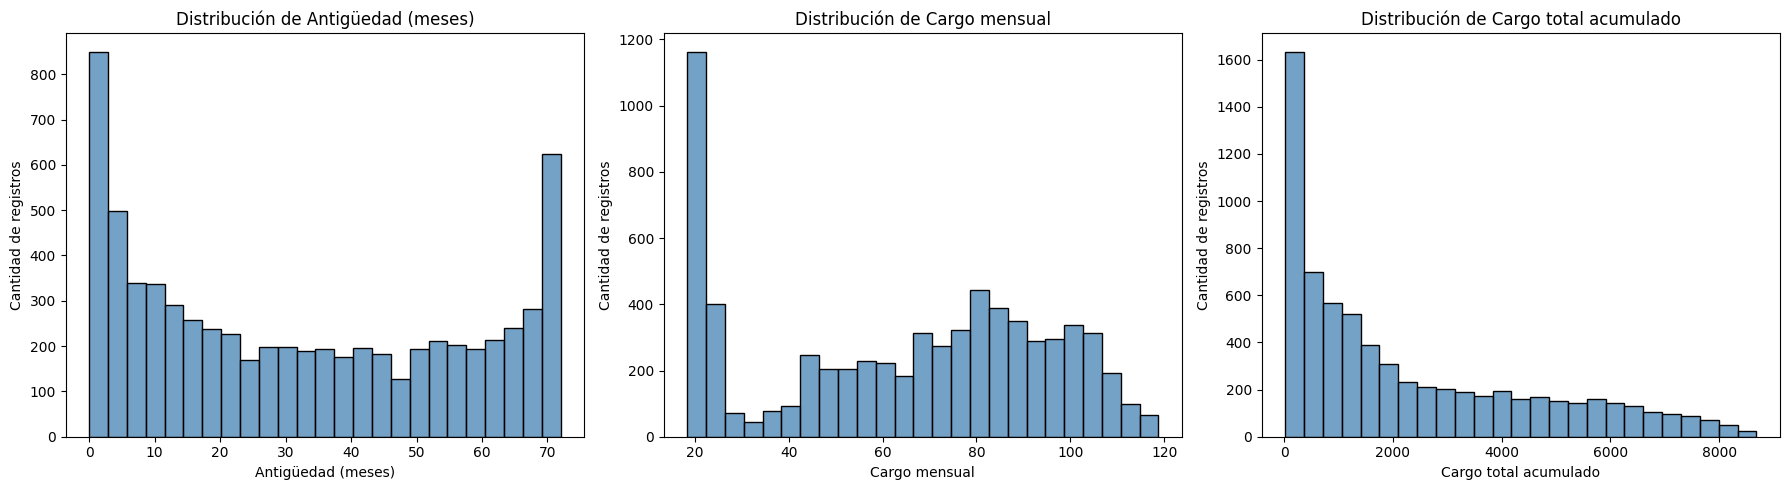

In [26]:
etiquetas = {
    "tenure": "Antigüedad (meses)",
    "MonthlyCharges": "Cargo mensual",
    "TotalCharges": "Cargo total acumulado"
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, columna in zip(axes, numericas):
    sns.histplot(
        data=df,
        x=columna,
        bins=25,
        color="steelblue",
        ax=ax
    )
    ax.set_title(f"Distribución de {etiquetas[columna]}")
    ax.set_xlabel(etiquetas[columna])
    ax.set_ylabel("Cantidad de registros")

plt.tight_layout()
plt.show()

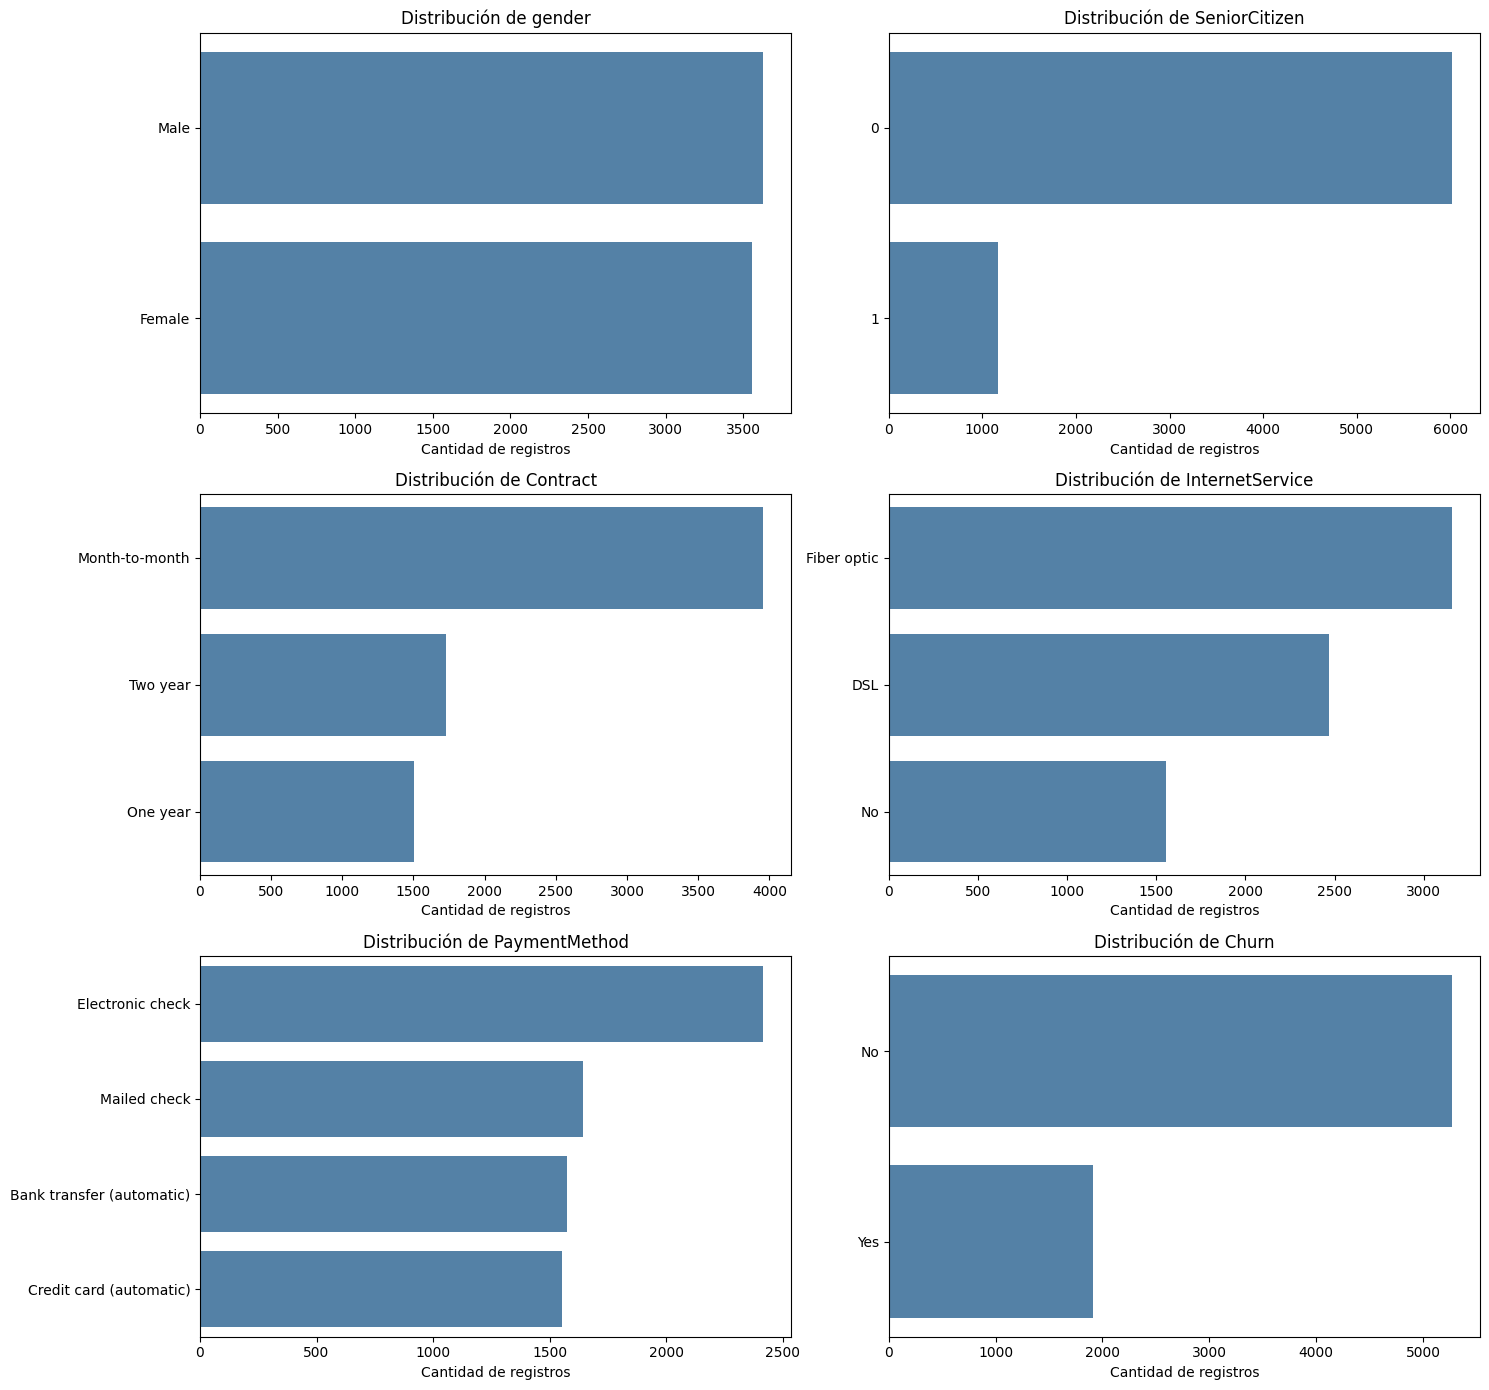

In [27]:
variables = [
    "gender", "SeniorCitizen", "Contract",
    "InternetService", "PaymentMethod", "Churn"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for ax, columna in zip(axes.flat, variables):
    sns.countplot(
        data=df,
        y=columna,
        order=df[columna].value_counts().index,
        color="steelblue",
        ax=ax
    )
    ax.set_title(f"Distribución de {columna}")
    ax.set_xlabel("Cantidad de registros")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

,Permanecieron,Abandonaron,Total,Abandono (%)
Contract,,,,
Month-to-month,2263,1693,3956,42.80
One year,1332,170,1502,11.32
Two year,1675,50,1725,2.90


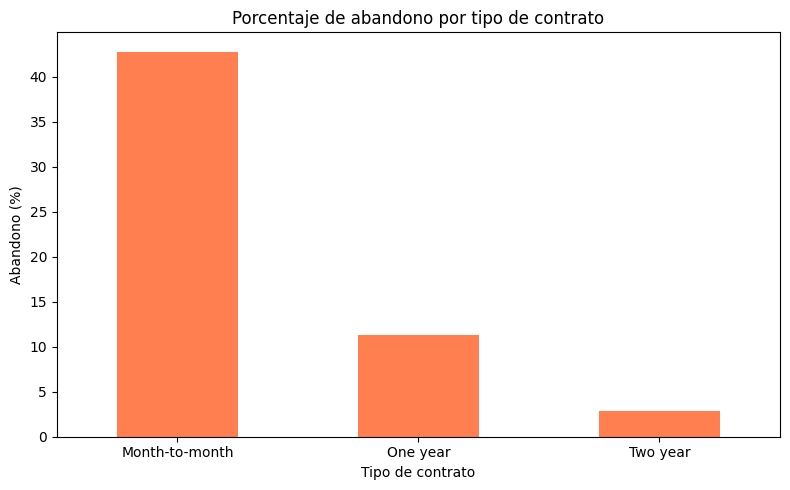

In [28]:
tabla = pd.crosstab(df["Contract"], df["Churn"])
tabla = tabla.reindex(columns=["No", "Yes"], fill_value=0)

tabla.columns = ["Permanecieron", "Abandonaron"]
tabla["Total"] = tabla["Permanecieron"] + tabla["Abandonaron"]
tabla["Abandono (%)"] = tabla["Abandonaron"] / tabla["Total"] * 100

display(tabla.round(2))

tabla["Abandono (%)"].plot(
    kind="bar",
    color="coral",
    figsize=(8, 5)
)

plt.title("Porcentaje de abandono por tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Abandono (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

| Variable | Descripción | Tipo de variable | Valores o unidad |
|---|---|---|---|
| `customerID` | Identificador único del cliente. | Categórica nominal | Código alfanumérico. |
| `gender` | Género registrado del cliente. | Categórica nominal | `Female`: femenino; `Male`: masculino. |
| `SeniorCitizen` | Indica si el cliente es adulto mayor. | Categórica binaria | `0`: no; `1`: sí. |
| `Partner` | Indica si el cliente tiene pareja. | Categórica binaria | `Yes`: sí; `No`: no. |
| `Dependents` | Indica si el cliente tiene personas dependientes. | Categórica binaria | `Yes`: sí; `No`: no. |
| `tenure` | Tiempo de permanencia del cliente en la empresa. | Numérica discreta | Meses; de 0 a 72 en el archivo. |
| `PhoneService` | Indica si el cliente tiene servicio telefónico. | Categórica binaria | `Yes`: sí; `No`: no. |
| `MultipleLines` | Indica si el cliente tiene varias líneas telefónicas. | Categórica nominal | `Yes`: sí; `No`: no; `No phone service`: sin servicio telefónico. |
| `InternetService` | Tipo de servicio de internet del cliente. | Categórica nominal | `DSL`; `Fiber optic`: fibra óptica; `No`: sin internet. |
| `OnlineSecurity` | Indica si el cliente tiene contratado un servicio de seguridad en línea. | Categórica nominal | `Yes`; `No`; `No internet service`: sin servicio de internet. |
| `OnlineBackup` | Indica si el cliente tiene contratado un servicio de respaldo en línea. | Categórica nominal | `Yes`; `No`; `No internet service`. |
| `DeviceProtection` | Indica si el cliente tiene contratado un servicio de protección de dispositivos. | Categórica nominal | `Yes`; `No`; `No internet service`. |
| `TechSupport` | Indica si el cliente tiene contratado soporte técnico. | Categórica nominal | `Yes`; `No`; `No internet service`. |
| `StreamingTV` | Indica si el cliente tiene contratado un servicio de televisión por streaming. | Categórica nominal | `Yes`; `No`; `No internet service`. |
| `StreamingMovies` | Indica si el cliente tiene contratado un servicio de películas por streaming. | Categórica nominal | `Yes`; `No`; `No internet service`. |
| `Contract` | Tipo de contrato del cliente. | Categórica nominal | `Month-to-month`: mensual; `One year`: un año; `Two year`: dos años. |
| `PaperlessBilling` | Indica si el cliente utiliza facturación electrónica, sin papel. | Categórica binaria | `Yes`: sí; `No`: no. |
| `PaymentMethod` | Método utilizado para realizar los pagos. | Categórica nominal | Cheque electrónico, cheque por correo, transferencia bancaria automática o tarjeta de crédito automática. |
| `MonthlyCharges` | Importe cobrado mensualmente al cliente. | Numérica continua | Unidades monetarias; de 18,25 a 118,75 en el archivo. |
| `TotalCharges` | Importe total acumulado cobrado al cliente. | Numérica continua; inicialmente almacenada como texto | Unidades monetarias. |
| `Churn` | Indica si el cliente abandonó el servicio. | Categórica binaria | `Yes`: abandonó; `No`: permaneció. |